# 🧪 MLP on MNIST (Keras)
This notebook demonstrates how to train a basic **Multi-Layer Perceptron (MLP)** on the **MNIST** dataset using **TensorFlow/Keras**.

By the end of this notebook, you will:
- Load and preprocess the MNIST dataset
- Build a dense neural network
- Train and evaluate the model
- Analyze training performance and overfitting


In [7]:
# 📦 Import libraries
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.utils import to_categorical


mnist : jeu de données de chiffres manuscrits

Sequential, Dense, Dropout, Flatten : composants du modèle MLP

to_categorical : transforme les étiquettes en one-hot encoding

matplotlib.pyplot : affichage de courbes

In [8]:
# 📥 Load and preprocess MNIST data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten the 28x28 images into 784-dimensional vectors
x_train = x_train.reshape((x_train.shape[0], -1))
x_test = x_test.reshape((x_test.shape[0], -1))

# One-hot encode the labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)


Charge les ensembles d'entraînement et de test

Normalise les pixels (valeurs entre 0 et 1)

Aplatis les images 28×28 en vecteurs de 784 éléments pour le MLP

Encode les étiquettes (0–9) en vecteurs one-hot (ex: 3 devient [0,0,0,1,0,0,0,0,0,0])

In [9]:
# 🏗️ Build the MLP model
model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(784,)))
model.add(Dropout(0.2))
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Crée un réseau séquentiel avec 3 couches :

Dense(128) : couche cachée avec 128 neurones et activation ReLU

Dropout(0.2) : désactive aléatoirement 20% des neurones à chaque epoch (pour éviter l’overfitting)

Dense(64) : seconde couche cachée

Dense(10, softmax) : couche de sortie à 10 classes

Compile le modèle avec :

Optimiseur Adam

Fonction de perte cross-entropy catégorique

Suivi de la précision (accuracy)

Affiche le résumé du modèle (nombres de paramètres, formes, etc.)

In [10]:
# 🏃‍♂️ Train the model
history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=128,
                    validation_split=0.2,
                    verbose=2)

Epoch 1/15
375/375 - 3s - 9ms/step - accuracy: 0.8737 - loss: 0.4313 - val_accuracy: 0.9512 - val_loss: 0.1689
Epoch 2/15
375/375 - 2s - 6ms/step - accuracy: 0.9480 - loss: 0.1783 - val_accuracy: 0.9627 - val_loss: 0.1250
Epoch 3/15
375/375 - 2s - 6ms/step - accuracy: 0.9609 - loss: 0.1323 - val_accuracy: 0.9650 - val_loss: 0.1118
Epoch 4/15
375/375 - 3s - 9ms/step - accuracy: 0.9669 - loss: 0.1081 - val_accuracy: 0.9722 - val_loss: 0.0982
Epoch 5/15
375/375 - 2s - 6ms/step - accuracy: 0.9716 - loss: 0.0922 - val_accuracy: 0.9737 - val_loss: 0.0886
Epoch 6/15
375/375 - 3s - 7ms/step - accuracy: 0.9754 - loss: 0.0808 - val_accuracy: 0.9737 - val_loss: 0.0868
Epoch 7/15
375/375 - 2s - 6ms/step - accuracy: 0.9776 - loss: 0.0704 - val_accuracy: 0.9750 - val_loss: 0.0867
Epoch 8/15
375/375 - 3s - 8ms/step - accuracy: 0.9796 - loss: 0.0627 - val_accuracy: 0.9758 - val_loss: 0.0846
Epoch 9/15
375/375 - 3s - 8ms/step - accuracy: 0.9818 - loss: 0.0571 - val_accuracy: 0.9754 - val_loss: 0.0852
E

Entraîne le modèle pendant 10 époques sur des lots de 128 images

Utilise 20% des données d'entraînement pour la validation

Stocke l'historique d'entraînement dans history pour analyse ultérieure

In [11]:
# 📊 Evaluate on test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.9772


Évalue la performance du modèle sur l’ensemble de test

Affiche la précision finale (Test Accuracy)

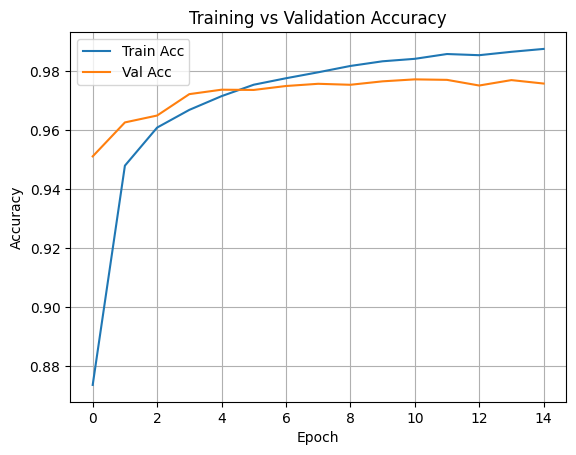

In [12]:
# 📈 Plot training history
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

Trace les courbes de précision pour :

les données d'entraînement (Train Acc)

les données de validation (Val Acc)

Permet d’observer :

L’apprentissage du modèle

La présence éventuelle de surapprentissage

